In [1]:
# --- repository root ---------------------------------------------------
# The notebooks live in notebooks/, the package in succd/, the data in data/.
# This cell finds the repository root (the folder holding pyproject.toml),
# makes it the working directory and puts it on sys.path, so that
# `from succd import ...` works without installing the package.
import os, sys
_d = os.path.abspath(os.getcwd())
while not os.path.isfile(os.path.join(_d, 'pyproject.toml')):
    if _d == os.path.dirname(_d):
        raise FileNotFoundError('repository root not found: expected a parent folder '
                                'holding pyproject.toml and succd/')
    _d = os.path.dirname(_d)
REPO = _d
os.environ['SUCCD_ROOT'] = REPO
os.chdir(REPO)
if REPO not in sys.path:
    sys.path.insert(0, REPO)
from succd import paths            # data folders: paths.RESULTS, paths.VALUES, paths.SI ...
print('repository root:', os.path.basename(REPO), '(found and set as working directory)')


repository root: selected-uccd (found and set as working directory)


# Supporting Information — the computed quantities

Same shape as notebook 4: small functions, one loop, tables, then figures.
The section, table and figure numbers of the submitted Supporting Information
are S1–S5, Tables S1–S8 and Figures S1–S4; the headings below carry the
numbering of the earlier draft this notebook was written against (see
`CHANGELOG.md` for the mapping).

| section | tables | figure | what it needs |
|---|---|---|---|
| 2 validity domain of the closed-form rescaling | Table 2 | S1 | a scan over bond length |
| 3 cost-free predictors of the optimal scale factor | Table 3 | S2 | the ray optimum |
| 4 parallelism of the parameterisations | Tables 4, 5, 6 | S3 | c and t component by component |
| 5 circuit cost of the singles block, accuracy condition | Tables 7, 8 | S4 | one extra transpilation |
| 6 noise condition for the SQD route | Table 8 | S5 | the sampled d_m state |

Needs the `succd` package (found automatically by the first cell) and the full
PySCF + Qiskit stack of `requirements.txt`.

## Setup

In [2]:
# qiskit-algorithms 0.4.0 has a circular import that fires on some installs
# when qiskit-nature first pulls it in; succd/__init__.py applies the
# workaround (see scripts/check_environment.py).
import os, sys, json, time, math, warnings, importlib
warnings.filterwarnings('ignore')

import succd
from succd import PySCFDriver_mod_vers
importlib.reload(PySCFDriver_mod_vers)     # pyscf_problem_extended reloads it too
CODE = os.path.dirname(os.path.abspath(succd.__file__))
print('package :', os.path.relpath(CODE, paths.ROOT), '| reload OK')

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar
from pyscf import gto, scf, cc, ci
from pyscf.fci import direct_spin1, cistring
from scipy.sparse.linalg import LinearOperator, eigsh
from math import comb

from succd import core, drv
from succd import selected_cc_pipeline as scp
K = core.K                        # Hartree -> kcal/mol


Ades Reigns
Ades Reigns
package : succd | reload OK


## Geometries

Angstrom, STO-6G. Second entry is the number of frozen core orbitals. Acetylene is `C2H2` here and in `succd/geoms.py`.

Section 1 does not use these: it builds its own stretched geometries.

In [3]:
H6 = """  H   -0.00000013033398     -0.00000027656978     -1.63585537349176
  H   -0.00000002026762     -0.00000001049860     -0.88216228307366
  H   0.00000005145092      0.00000026737096      2.12317470217342
  H   0.00000019741506      0.00000028652252      2.87682413358394
  H   0.00000001191796      0.00000000445340      5.88216389396856
  H   -0.00000011018233     -0.00000027127849      6.63585492683949"""

H8 = """  H   0.00000014047129      0.00000007179489     -2.49463655320066
  H   0.00000005471022      0.00000003978284     -1.74094036515667
  H   -0.00000000410940     -0.00000006874485      1.24863503981317
  H   -0.00000012507223     -0.00000010066620      2.00229939584808
  H   -0.00000019452856     -0.00000006736999      4.99770518795901
  H   -0.00000012436358      0.00000002198468      5.75136984133156
  H   0.00000006114635     -0.00000000235498      8.74093595148680
  H   0.00000019174591      0.00000010557361      9.49463150191870"""

N2 = """  N   0.00000000000000      0.00000000000000      0.03808486286764
  N   0.00000000000000      0.00000000000000      1.16191513713236"""

CO = """  O   -1.07180221708728      0.00000000000000      0.00000000000000
  C   0.07180221708728      0.00000000000000      0.00000000000000"""

CH2O = """  H   1.07578703937518     -0.14380969167056      1.05707279366277
  C   0.59552162304750      0.01521281882427      0.06858835087804
  H   1.27921938071923      0.20323734246116     -0.78595667392319
  O   -0.61132804314190     -0.01554046961487     -0.07040447061762"""

C2H2 = """  C   0.59610628651506      0.01277743826555      0.14122987213962
  C   -0.59608390436389     -0.01275984381194     -0.14117151138292
  H   1.63992701862499      0.03514052846642      0.38864357314535
  H   -1.63994940077616     -0.03505812292003     -0.38840193390205"""

GEOM = {'H6':   (H6,   0),
        'H8':   (H8,   0),
        'N2':   (N2,   2),
        'CO':   (CO,   2),
        'CH2O': (CH2O, 2),
        'C2H2': (C2H2, 2)}
BASIS = 'sto-6g'
ALL = ['H6', 'N2', 'CO', 'H8', 'CH2O', 'C2H2']       # cheapest first

core.SYSTEMS = GEOM                        # these geometries are authoritative
from succd import geoms
geoms.SYSTEMS.clear(); geoms.SYSTEMS.update(GEOM)

for k, (g, nf) in GEOM.items():
    print('%-5s frozen=%d  atoms=%d' % (k, nf, len(g.strip().splitlines())))

H6    frozen=0  atoms=6
H8    frozen=0  atoms=8
N2    frozen=2  atoms=2
CO    frozen=2  atoms=2
CH2O  frozen=2  atoms=4
C2H2  frozen=2  atoms=4


## Config

`DELTA` matches `09_all.ipynb`. The stretching scan of Section 1 rebuilds everything from
scratch at each bond length, so it is the expensive part — `N2` is cheap, `H8` less so, and
the twenty-qubit molecules are not scanned at all in the article.

In [4]:
RUN   = ALL                       # all six systems; ['H6', 'N2'] for a quick run
TAG   = 'SI'
DELTA = 3e-4                      # same threshold as 09_all.ipynb

# Section 2: bond lengths / spacings to scan. Empty list skips a system.
STRETCH = {'N2': [1.10, 1.30, 1.50, 1.70],
           'H8': [0.90, 1.00, 1.10, 1.20, 1.30, 1.40]}

FIDELITY = 0.9977                 # median two-qubit fidelity, Ref. 70
EPSILONS = [0.01, 0.05, 0.10]     # Table 8 accuracy targets

core.DELTA = DELTA
BIG    = {'CH2O', 'C2H2'}
ROOT   = paths.ROOT
FIGDIR = os.path.join(ROOT, 'figures_%s' % TAG)
VALDIR = os.path.join(ROOT, 'values_%s' % TAG)
os.makedirs(FIGDIR, exist_ok=True); os.makedirs(VALDIR, exist_ok=True)
print('run', RUN, '| delta', DELTA, '| stretch', {k: len(v) for k, v in STRETCH.items()})

run ['H6', 'N2', 'CO', 'H8', 'CH2O', 'C2H2'] | delta 0.0003 | stretch {'N2': 4, 'H8': 6}


## The functions

One job each, one molecule at a time.

In [5]:
from scipy.optimize import minimize_scalar
from math import comb
from pyscf.fci import direct_spin1, cistring
from scipy.sparse.linalg import LinearOperator, eigsh
from qiskit import transpile
from qiskit.circuit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate
from qiskit_nature.second_q.circuit.library import HartreeFock
from qiskit_nature.second_q.mappers import JordanWignerMapper


def f_build(name):
    return core.build(name)


def f_select(C):
    scores = np.sort(np.abs(C['dfr']['E2_i'].values))[::-1]
    return core.nsel(C), scores


def f_classical(C, N):
    P = core.params(C, N, False)
    P['alpha_est'] = (2 - P['c0']**2) / P['c0']
    P['dm'] = P['alpha_est'] * P['c']
    return P


# ---------------------------------------------------------------- Section 3
def f_predictors(C, N, P, big=False):
    """Where the optimum along the c_m ray actually is, and how well the two
    cost-free predictors 1/c0 and alpha_est reach it.

    f is the fraction of the energy interval between E(c_m) and E(alpha*) that a
    prediction recovers; f = 1 means the prediction is the optimum."""
    Ev = core.evaluator(C)
    if big:
        grid = [1.05, 1.10, 1.15, 1.20]
        E = [float(Ev(a * P['c'], N)) for a in grid]
        i = int(np.argmin(E)); sl = slice(max(0, i-1), i+2)
        q = np.polyfit(grid[sl], E[sl], 2)
        astar = float(-q[1] / (2*q[0])); Ea = float(np.polyval(q, astar))
    else:
        r = minimize_scalar(lambda a: Ev(a * P['c'], N), bracket=(1.0, 1.15),
                            method='brent', options={'xtol': 1e-6})
        astar, Ea = float(r.x), float(r.fun)

    E_c  = float(Ev(P['c'], N))
    E_cp = float(Ev(P['cp'], N))
    E_d  = float(Ev(P['dm'], N))
    gap  = Ea - E_c
    frac = lambda e: (e - E_c) / gap if abs(gap) > 1e-12 else float('nan')

    tmp = C['dfr']['t_mp'].values[:N].astype(float)
    rho_mp = float(np.abs(tmp).sum() / np.abs(P['c']).sum())

    return dict(c0=P['c0'], alpha_star=astar, E_alpha=Ea,
                inv_c0=1.0 / P['c0'], f_inv_c0=frac(E_cp),
                alpha_est=P['alpha_est'],
                ratio_est_star=P['alpha_est'] / astar, f_alpha_est=frac(E_d),
                penalty=E_d - Ea, rho_mp=rho_mp, rho_mp_over_c0=rho_mp / P['c0'],
                E_cm=E_c, E_cpm=E_cp, E_dm=E_d)


# ---------------------------------------------------------------- Section 4
def f_parallel(C, N, P):
    """How nearly parallel the s-CID coefficient vector and the s-CCD amplitude
    vector are, component by component, and whether the MP1 phases the circuit
    receives agree with the converged s-CCD signs."""
    dbl = [tuple(map(int, x)) for x in C['dbl'][:N]]
    _, _, t2 = scp.SelectedCCSD(C['fock'], C['g'], C['nocc'], C['nvirt'],
                                selected_singles=[], selected_doubles=dbl,
                                so_labels=C['lbl']).kernel()
    t_raw = np.array([t2[i, j, a, b] for (i, j, a, b) in dbl], dtype=float)
    s_mp1 = np.sign(C['dfr']['t_mp'].values[:N]).astype(float)

    c, t = P['c'], P['t']
    ac, at = np.abs(c), np.abs(t)
    ratio = at / ac
    mean = float(ratio.mean())
    dev = np.abs(ratio - mean) / mean * 100.0
    order = np.argsort(ac); half = N // 2
    cos1 = float(c @ t / (np.linalg.norm(c) * np.linalg.norm(t)))
    cos2 = float(c @ t_raw / (np.linalg.norm(c) * np.linalg.norm(t_raw)))
    nr = float(np.linalg.norm(t) / np.linalg.norm(c))

    return dict(N=N,
                cos_eq6=cos1, theta_eq6=float(np.degrees(np.arccos(min(1.0, cos1)))),
                cos_sccd=cos2, theta_sccd=float(np.degrees(np.arccos(min(1.0, cos2)))),
                signs_opposed=int((np.sign(t_raw) != s_mp1).sum()),
                mean_ratio=mean,
                spread_pct=float((ratio.max() - ratio.min()) / mean * 100),
                dev_small_half=float(dev[order[:half]].mean()),
                dev_large_half=float(dev[order[half:]].mean()),
                corr_logmag_dev=float(np.corrcoef(np.log(ac), dev)[0, 1]),
                norm_ratio=nr, alpha_est=P['alpha_est'], inv_c0=1.0 / P['c0'],
                err_alpha_est=100 * (P['alpha_est'] / nr - 1),
                err_inv_c0=100 * (1.0 / P['c0'] / nr - 1),
                ratios=ratio.tolist())


# ---------------------------------------------------------------- Section 5
def _counts(C, ops):
    hf = HartreeFock(C['M'], C['npart'], JordanWignerMapper())
    q = QuantumCircuit(hf.num_qubits); q.compose(hf, inplace=True)
    for o in ops:
        q.append(PauliEvolutionGate(o, time=0.1), range(hf.num_qubits))
    t = transpile(q, basis_gates=['cx', 'rz', 'sx', 'x'],
                  optimization_level=1, seed_transpiler=7)
    d = dict(t.count_ops())
    return dict(depth=t.depth(), cx=d.get('cx', 0), total=sum(d.values()))


def f_singles_cost(C, N):
    """The cost of the singles block, obtained by subtraction: the same circuit with
    and without every single of the active space appended.

    C['mapped'] has already been pruned to the N selected doubles by f_select, so the
    full pool has to come from em_jw, the complete excitation list."""
    em, mp, sidx = C['em_jw'], C['mapped'], C['singles_idx']
    sel  = [em[mp[k]] for k in range(N)]
    sgl  = [em[sidx[k]] for k in range(len(sidx))]
    c_d  = _counts(C, sel)
    c_ds = _counts(C, sel + sgl)
    c_f  = _counts(C, [o for o in em if o is not None])
    ns = len(sidx)
    return dict(n_singles=ns, cx_sUCCD=c_d['cx'], cx_with_singles=c_ds['cx'],
                cx_singles_block=c_ds['cx'] - c_d['cx'],
                cx_per_single=(c_ds['cx'] - c_d['cx']) / ns if ns else float('nan'),
                cx_per_double=c_d['cx'] / N,
                cx_UCCSD=c_f['cx'], total_sUCCD=c_d['total'], depth_sUCCD=c_d['depth'])


# ---------------------------------------------------------------- Section 6
def f_noise(C, N, P, fidelity=None):
    """Eq. 11. A configuration of weight w clears the depolarised background when
    p w >= (1-p)/D, so the binding one is the weakest still needed to reach 95 % of
    the correlation energy of the populated space."""
    fidelity = FIDELITY if fidelity is None else fidelity
    psi = core.state(C, P['dm']); w = np.abs(psi)**2; w /= w.sum()
    M, na, nb = C['M'], C['na'], C['nb']
    ns = cistring.num_strings(M, na); msk = (1 << M) - 1
    h2e = direct_spin1.absorb_h1e(C['h1'], C['eri'], M, (na, nb), .5)
    idx = [i for i in np.where(w > 1e-14)[0]
           if bin(int(i) & msk).count('1') == na
           and bin((int(i) >> M) & msk).count('1') == nb]
    order = sorted(idx, key=lambda i: -w[i])

    def en(sub):
        a = np.unique([cistring.str2addr(M, na, int(i) & msk) * ns +
                       cistring.str2addr(M, nb, (int(i) >> M) & msk) for i in sub])
        def mv(x):
            v = np.zeros(ns*ns); v[a] = x
            return direct_spin1.contract_2e(h2e, v.reshape(ns, ns),
                                            M, (na, nb)).ravel()[a]
        l = eigsh(LinearOperator((len(a),)*2, matvec=mv, dtype=float), k=1,
                  which='SA', tol=1e-10, maxiter=40000)[0][0]
        return float((l + C['shift']) * K)

    tgt = 0.95 * en(order); lo, hi = 1, len(order)
    while lo < hi:
        mid = (lo + hi) // 2
        if en(order[:mid]) <= tgt: hi = mid
        else: lo = mid + 1
    wmin = float(w[order[lo-1]]); D = comb(M, na) * comb(M, nb)
    p = 1.0 / (1.0 + D * wmin)
    return dict(dets_95=lo, populated=len(order), D=D, w_min=wmin, D_wmin=D*wmin,
                p_required=p, N_CX=int(math.floor(math.log(p) / math.log(fidelity))))

## Section 1 — the stretching scan

A separate function, because it does not start from the equilibrium geometries: at each
bond length the whole construction is repeated from scratch, so the prediction is always
scored against the optimum at that geometry rather than against the equilibrium one.

Conventions follow the shipped scan: N2 is `N 0 0 0 / N 0 0 R`, H8 is the uniform linear
chain, so R is the spacing.

In [6]:
def f_stretch_point(system, R):
    xyz = ('N 0 0 0; N 0 0 %.6f' % R) if system == 'N2' else \
          '; '.join('H 0 0 %.6f' % (i * R) for i in range(8))
    nfz = 2 if system == 'N2' else 0
    Cx = scp.build_union_context(xyz, basis=BASIS, n_frozen=nfz, verbose=False)
    Cx['_tap'] = (Cx.get('Hmat') is not None and Cx.get('gens_tap') is not None)
    N = core.nsel(Cx)
    Ev = core.evaluator(Cx)
    sg = np.sign(Cx['dfr']['t_mp'].values[:N]).astype(float)
    Ecid, vec = scp.ci_corr([Cx['HFdet']] + Cx['double_dets'][:N], Cx['h1'], Cx['eri'])
    c0 = abs(vec[0]); cm = np.abs(vec[1:1+N])
    a_est = (2 - c0**2) / c0
    r = minimize_scalar(lambda a: Ev(a * cm * sg, N), bracket=(1.0, 1.2),
                        method='brent', options={'xtol': 1e-6})
    astar, Ea = float(r.x), float(r.fun)
    E_c = float(Ev(cm * sg, N))
    E_d = float(Ev(a_est * cm * sg, N))
    gap = Ea - E_c
    return dict(system=system, R=R, N=N, c0=c0, alpha_star=astar, alpha_est=a_est,
                E_alpha=Ea, E_cm=E_c, E_dm=E_d, penalty=E_d - Ea,
                f_alpha_est=(E_d - E_c)/gap if abs(gap) > 1e-12 else float('nan'),
                E_sCID=float(Ecid * K))

## The loop

In [7]:
SI = {}
T0 = time.time()
for name in RUN:
    t0 = time.time()
    print('--- %s ---' % name, flush=True)
    Cx = f_build(name)
    N, scores = f_select(Cx)
    P = f_classical(Cx, N)
    pred = f_predictors(Cx, N, P, big=name in BIG)
    par  = f_parallel(Cx, N, P)
    gate = f_singles_cost(Cx, N)
    noi  = f_noise(Cx, N, P)
    print('  N %d   c0 %.5f   alpha* %.4f   alpha_est %.4f   penalty %.3f'
          % (N, P['c0'], pred['alpha_star'], pred['alpha_est'], pred['penalty']))
    print('  cos(Eq.6) %.8f   theta %.3f deg   signs opposed %d'
          % (par['cos_eq6'], par['theta_eq6'], par['signs_opposed']))
    print('  singles %d   CX block %d   CX/single %.1f   CX/double %.1f'
          % (gate['n_singles'], gate['cx_singles_block'],
             gate['cx_per_single'], gate['cx_per_double']))
    print('  dets95 %d of %d   D w_min %.4f   admits %d CX   (%.0f s)'
          % (noi['dets_95'], noi['populated'], noi['D_wmin'], noi['N_CX'],
             time.time() - t0))
    rec = {'molecule': name}
    for part in (pred, par, gate, noi):     # later parts win where keys repeat
        rec.update(part)
    SI[name] = rec

STRETCH_ROWS = []
for system, Rs in STRETCH.items():
    for R in Rs:
        t0 = time.time()
        row = f_stretch_point(system, R)
        STRETCH_ROWS.append(row)
        print('  %-3s R=%.2f  N %3d  c0 %.4f  alpha* %.4f  alpha_est %.4f  '
              'penalty %8.3f  (%.0f s)'
              % (system, R, row['N'], row['c0'], row['alpha_star'],
                 row['alpha_est'], row['penalty'], time.time() - t0), flush=True)

print('total %.0f s' % (time.time() - T0))

store = os.path.join(VALDIR, 'si_results.json')
prev = json.load(open(store)) if os.path.exists(store) else {'molecules': {}, 'stretch': []}
prev['molecules'].update(SI)
seen = {(r['system'], round(r['R'], 4)) for r in STRETCH_ROWS}
prev['stretch'] = STRETCH_ROWS + [r for r in prev.get('stretch', [])
                                  if (r['system'], round(r['R'], 4)) not in seen]
json.dump(prev, open(store, 'w'), indent=1)
SI, STRETCH_ROWS = prev['molecules'], prev['stretch']
print('molecules on file:', list(SI), '| stretch points:', len(STRETCH_ROWS))

--- H6 ---


Ades Reigns
['1A', '2A', '3A', '4A', '5A', '6A', '1B', '2B', '3B', '4B', '5B', '6B']




 Other important parts for the problem created now.
        
        A. Number of spin orbitals is: 12
        B. The number of JW configuration is: 2^12 =  4096
        C. Hence the JW matrix is a: 12 x 12
        D. Occupied orbitals: 3
        E. Unoccupied orbitals: 3
         



Time for JW Mapping:  4.313508749008179 



Time for Tapering Symmerties:  2.26615309715271 



Elimination of Useless column saved into: df2
Elimination of Useless column Active in df1


time for mapper NON TAPERING: 4.921260118484497


... (104 outputs left out)

time for mapper NON TAPERING: 8.693517208099365


start selection


  H8  R=1.40  N 100  c0 0.8675  alpha* 1.3170  alpha_est 1.4379  penalty    1.365  (31 s)


total 1008 s
molecules on file: ['H6', 'N2', 'CO', 'H8', 'CH2O', 'C2H2'] | stretch points: 10


## The tables

`ORDER` is whatever was actually run, in the order the article uses.

In [8]:
ORDER = [m for m in ['C2H2', 'N2', 'CH2O', 'CO', 'H8', 'H6'] if m in SI]
PRETTY = {'H6': r'$\mathrm{H_6}$', 'H8': r'$\mathrm{H_8}$', 'N2': r'$\mathrm{N_2}$',
          'CO': r'$\mathrm{CO}$', 'CH2O': r'$\mathrm{CH_2O}$',
          'C2H2': r'$\mathrm{C_2H_2}$'}

def build(cols, rows=None, index=None):
    rows = ORDER if rows is None else rows
    df = pd.DataFrame({n: [SI[m][k] for m in rows] for n, k in cols},
                      index=index if index is not None else rows)
    df.index.name = 'molecule'
    return df

def show(df, title, fname, fmt=None):
    df.to_csv(os.path.join(VALDIR, '%s_%s.csv' % (TAG, fname)))
    print('=' * 78); print(title); print('=' * 78)
    with pd.option_context('display.width', 250, 'display.max_columns', 40):
        print(df.to_string(formatters=fmt) if fmt else df.to_string())
    print()

### Table 2 — validity domain under stretching

In [9]:
if STRETCH_ROWS:
    T2 = pd.DataFrame([{'system': r['system'], 'R / A': r['R'], 'N': r['N'],
                        'c0': r['c0'], 'alpha*': r['alpha_star'],
                        'alpha_est': r['alpha_est'], 'penalty': r['penalty'],
                        'f(alpha_est)': r['f_alpha_est']}
                       for r in sorted(STRETCH_ROWS,
                                       key=lambda r: (r['system'], r['R']))])
    T2 = T2.set_index(['system', 'R / A'])
    T2.to_csv(os.path.join(VALDIR, '%s_table2_stretch.csv' % TAG))
    print('Table 2 — the closed form against the located optimum, geometry by geometry')
    print(T2.to_string(float_format=lambda v: '%.4f' % v))
else:
    T2 = pd.DataFrame()
    print('no stretch points; set STRETCH to run Section 2')

Table 2 — the closed form against the located optimum, geometry by geometry
                N     c0  alpha*  alpha_est  penalty  f(alpha_est)
system R / A                                                      
H8     0.9     52 0.9621  1.0704     1.1167   0.1081        0.5688
       1.0     60 0.9468  1.1034     1.1656   0.2287        0.6397
       1.1     66 0.9295  1.1431     1.2223   0.4251        0.6954
       1.2     80 0.9102  1.1925     1.2872   0.6915        0.7597
       1.3     96 0.8898  1.2505     1.3580   0.9965        0.8183
       1.4    100 0.8675  1.3170     1.4379   1.3652        0.8572
N2     1.1     39 0.9662  1.1197     1.1039   0.0184        0.9827
       1.3     39 0.9465  1.2108     1.1666   0.1679        0.9568
       1.5     43 0.9051  1.3030     1.3046   0.0003        1.0000
       1.7     39 0.8229  1.1831     1.6074  16.4211       -2.9567


### Table 3 — cost-free predictors

In [10]:
T3 = build([('c0', 'c0'), ('alpha*', 'alpha_star'), ('1/c0', 'inv_c0'),
            ('f(1/c0)', 'f_inv_c0'), ('alpha_est', 'alpha_est'),
            ('alpha_est/alpha*', 'ratio_est_star'), ('f(alpha_est)', 'f_alpha_est'),
            ('penalty', 'penalty'), ('rho_MP', 'rho_mp'),
            ('rho_MP/c0', 'rho_mp_over_c0')])
show(T3, 'Table 3 — how close the two cost-free predictors come to the ray optimum',
     'table3_predictors', {c: '{:.4f}'.format for c in T3.columns})

Table 3 — how close the two cost-free predictors come to the ray optimum
             c0 alpha*   1/c0 f(1/c0) alpha_est alpha_est/alpha* f(alpha_est) penalty rho_MP rho_MP/c0
molecule                                                                                              
C2H2     0.9575 1.1496 1.0444  0.5071    1.1314           0.9842       0.9854  0.0248 1.0269    1.0725
N2       0.9642 1.1287 1.0371  0.4950    1.1101           0.9835       0.9792  0.0262 1.1378    1.1801
CH2O     0.9625 1.0886 1.0390  0.6871    1.1155           1.0247       0.9082  0.0497 0.9166    0.9523
CO       0.9715 1.0910 1.0294  0.5417    1.0873           0.9966       0.9983  0.0009 1.0762    1.1078
H8       0.9799 1.0521 1.0205  0.6332    1.0612           1.0087       0.9694  0.0032 0.6883    0.7024
H6       0.9819 1.0412 1.0185  0.6952    1.0550           1.0133       0.8876  0.0068 0.6699    0.6822



### Tables 4, 5, 6 — parallelism

In [11]:
T4 = build([('N', 'N'), ('cos theta (Eq. 6)', 'cos_eq6'),
            ('theta / deg', 'theta_eq6'), ('cos theta (s-CCD)', 'cos_sccd'),
            ('theta_sCCD / deg', 'theta_sccd'), ('signs opposed', 'signs_opposed')])
show(T4, 'Table 4 — angle between the coefficient and amplitude vectors',
     'table4_angles',
     {'cos theta (Eq. 6)': '{:.8f}'.format, 'cos theta (s-CCD)': '{:.8f}'.format,
      'theta / deg': '{:.4f}'.format, 'theta_sCCD / deg': '{:.4f}'.format})

T5 = build([('mean |t|/|c|', 'mean_ratio'), ('spread %', 'spread_pct'),
            ('dev, small half %', 'dev_small_half'),
            ('dev, large half %', 'dev_large_half'),
            ('corr(log|c|, dev)', 'corr_logmag_dev')])
show(T5, 'Table 5 — the component-wise ratio, and where it departs from its mean',
     'table5_component_ratio', {c: '{:.4f}'.format for c in T5.columns})

T6 = build([('||t||/||c||', 'norm_ratio'), ('alpha_est', 'alpha_est'),
            ('1/c0', 'inv_c0'), ('alpha_est error %', 'err_alpha_est'),
            ('1/c0 error %', 'err_inv_c0')])
show(T6, 'Table 6 — the norm ratio, and the two predictors of it',
     'table6_norm_ratio', {c: '{:.4f}'.format for c in T6.columns})

Table 4 — angle between the coefficient and amplitude vectors
           N cos theta (Eq. 6) theta / deg cos theta (s-CCD) theta_sCCD / deg  signs opposed
molecule                                                                                    
C2H2      71        0.99979439      1.1619        0.99979439           1.1619              0
N2        39        0.99990722      0.7805        0.99990722           0.7805              0
CH2O      65        0.99993322      0.6622        0.99993322           0.6622              0
CO        49        0.99995210      0.5608        0.99995210           0.5608              0
H8        64        0.99999704      0.1394        0.99999704           0.1394              0
H6        35        0.99999978      0.0383        0.99999978           0.0383              0

Table 5 — the component-wise ratio, and where it departs from its mean
         mean |t|/|c| spread % dev, small half % dev, large half % corr(log|c|, dev)
molecule                             

### Tables 7, 8 — circuit cost of the singles block, and the accuracy condition

In [12]:
T7 = build([('singles', 'n_singles'), ('CX, singles block', 'cx_singles_block'),
            ('CX per single', 'cx_per_single'), ('N', 'N'),
            ('CX, s-UCCD', 'cx_sUCCD'), ('CX per double', 'cx_per_double')])
show(T7, 'Table 7 — what the singles block costs, by subtraction', 'table7_gate_cost',
     {'CX per single': '{:.1f}'.format, 'CX per double': '{:.1f}'.format})

per_double = [SI[m]['cx_per_double'] for m in ORDER]
corr = [abs(SI[m]['E_dm']) for m in ORDER]
T8 = pd.DataFrame([
    dict(**{'target error': '%d %%' % round(100*eps),
            'admitted N_CX': int(math.floor(math.log(1-eps)/math.log(FIDELITY))),
            'energy, smallest case': min(corr)*eps,
            'energy, largest case': max(corr)*eps,
            'doubles at %.0f CX each' % max(per_double):
                int(math.floor(math.log(1-eps)/math.log(FIDELITY)) // max(per_double)),
            'doubles at 13 CX each':
                int(math.floor(math.log(1-eps)/math.log(FIDELITY)) // 13)})
    for eps in EPSILONS]).set_index('target error')
T8.to_csv(os.path.join(VALDIR, '%s_table8_accuracy.csv' % TAG))
print('=' * 78)
print('Table 8 — how many two-qubit gates a given accuracy target allows, at f = %.4f'
      % FIDELITY)
print('=' * 78)
print(T8.to_string(float_format=lambda v: '%.3f' % v)); print()

Table 7 — what the singles block costs, by subtraction
          singles  CX, singles block CX per single   N  CX, s-UCCD CX per double
molecule                                                                        
C2H2           50               1000          20.0  71       10660         150.1
N2              2                 42          21.0  39        4652         119.3
CH2O           48                960          20.0  65        8940         137.5
CO             10                168          16.8  49        5664         115.6
H8             32                512          16.0  64        8448         132.0
H6             18                216          12.0  35        3696         105.6

Table 8 — how many two-qubit gates a given accuracy target allows, at f = 0.9977
              admitted N_CX  energy, smallest case  energy, largest case  doubles at 150 CX each  doubles at 13 CX each
target error                                                                                   

### Table 8 — the SQD noise condition

In [13]:
T9 = build([('dets for 95 %', 'dets_95'), ('populated', 'populated'),
            ('D', 'D'), ('w_min', 'w_min'), ('D w_min', 'D_wmin'),
            ('required p', 'p_required'), ('N_CX', 'N_CX')])
show(T9, 'Table 9 — the gate budget the sampled route tolerates', 'table9_sqd_noise',
     {'w_min': '{:.3e}'.format, 'D w_min': '{:.4f}'.format,
      'required p': '{:.4f}'.format})

Table 9 — the gate budget the sampled route tolerates
          dets for 95 %  populated      D     w_min D w_min required p  N_CX
molecule                                                                    
C2H2               1074       3297  63504 1.910e-08  0.0012     0.9988     0
N2                   48        220   3136 7.771e-05  0.2437     0.8041    94
CH2O                295       2919  44100 7.465e-07  0.0329     0.9681    14
CO                   52        302   3136 4.295e-05  0.1347     0.8813    54
H8                   63        442   4900 2.529e-04  1.2391     0.4466   350
H6                   39         84    400 2.805e-05  0.0112     0.9889     4



## Figures

Same style as the article figures: large type, black-edged bars, rotated numerals.

In [14]:
plt.rcParams.update({
    'font.size': 28, 'xtick.labelsize': 28, 'ytick.labelsize': 28,
    'axes.linewidth': 2.0, 'xtick.major.size': 9, 'ytick.major.size': 9,
    'xtick.major.width': 2.0, 'ytick.major.width': 2.0,
    'legend.framealpha': 1.0, 'legend.edgecolor': '0.75',
    'legend.borderpad': 0.45, 'legend.handlelength': 1.5,
    'legend.columnspacing': 1.1, 'legend.labelspacing': 0.35,
    'grid.linestyle': ':', 'grid.linewidth': 1.4, 'grid.color': '0.78',
    'hatch.linewidth': 2.2, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.06})
FS_ANNOT, FS_LEG, FS_LAB, FS_MOL, DPI = 23, 22, 25, 27, 600
RED, GOLD, BLUE, GREY, DARK = '#c0392b', '#f4b41a', '#4878a8', '#9aa5b1', '#4f4f4f'
labels = [PRETTY[m] for m in ORDER]
x = np.arange(len(ORDER))

def annot(ax, xs, vs, top, fmt='%.2f'):
    pad = 0.012 * (top - ax.get_ylim()[0])
    for xi, v in zip(xs, vs):
        if np.isfinite(v):
            ax.text(xi, v + pad, fmt % v, rotation=90, ha='center', va='bottom',
                    fontsize=FS_ANNOT, clip_on=False)

def save(fig, short):
    fig.tight_layout()
    p = os.path.join(FIGDIR, '%s_%s.png' % (TAG, short))
    fig.savefig(p, dpi=DPI); print('wrote', os.path.basename(p))
    plt.show()

### Figure S1 — validity domain

wrote SI_figS1_validity_domain.png


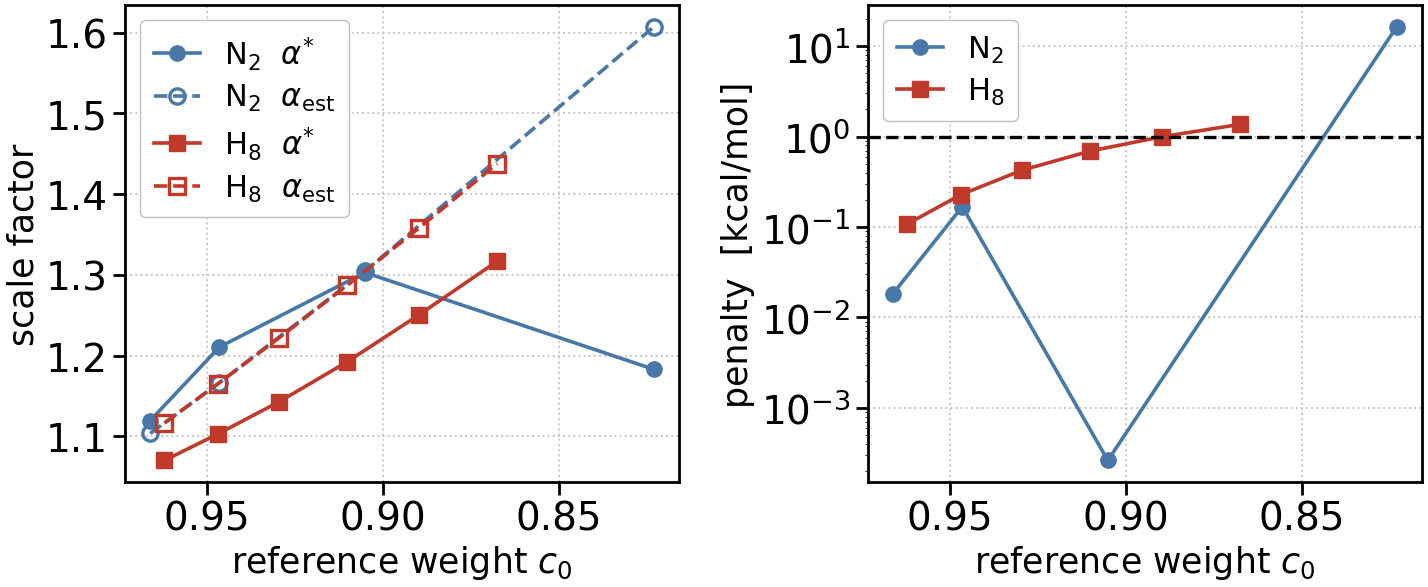

In [15]:
if STRETCH_ROWS:
    fig, axs = plt.subplots(1, 2, figsize=(15.0, 6.6))
    for sysname, col, mk in (('N2', BLUE, 'o'), ('H8', RED, 's')):
        r = sorted([p for p in STRETCH_ROWS if p['system'] == sysname],
                   key=lambda p: -p['c0'])
        if not r:
            continue
        c0 = [p['c0'] for p in r]
        axs[0].plot(c0, [p['alpha_star'] for p in r], mk + '-', color=col,
                    ms=11, lw=2.6, label=r'%s  $\alpha^{*}$' % PRETTY[sysname])
        axs[0].plot(c0, [p['alpha_est'] for p in r], mk + '--', color=col, ms=11,
                    lw=2.6, mfc='none', mew=2.4,
                    label=r'%s  $\alpha_{\mathrm{est}}$' % PRETTY[sysname])
        axs[1].semilogy(c0, [max(p['penalty'], 1e-4) for p in r], mk + '-',
                        color=col, ms=11, lw=2.6, label=PRETTY[sysname])
    axs[0].set_xlabel(r'reference weight $c_0$', fontsize=FS_LAB)
    axs[0].set_ylabel('scale factor', fontsize=FS_LAB)
    axs[1].axhline(1.0, color='black', ls='--', lw=2.4)
    axs[1].set_xlabel(r'reference weight $c_0$', fontsize=FS_LAB)
    axs[1].set_ylabel('penalty  [kcal/mol]', fontsize=FS_LAB)
    for ax in axs:
        ax.invert_xaxis(); ax.grid(True, zorder=0); ax.set_axisbelow(True)
        ax.legend(fontsize=FS_LEG)
    save(fig, 'figS1_validity_domain')
else:
    print('Section 2 not run')

### Figure S2 — predictors

wrote SI_figS2_predictors.png


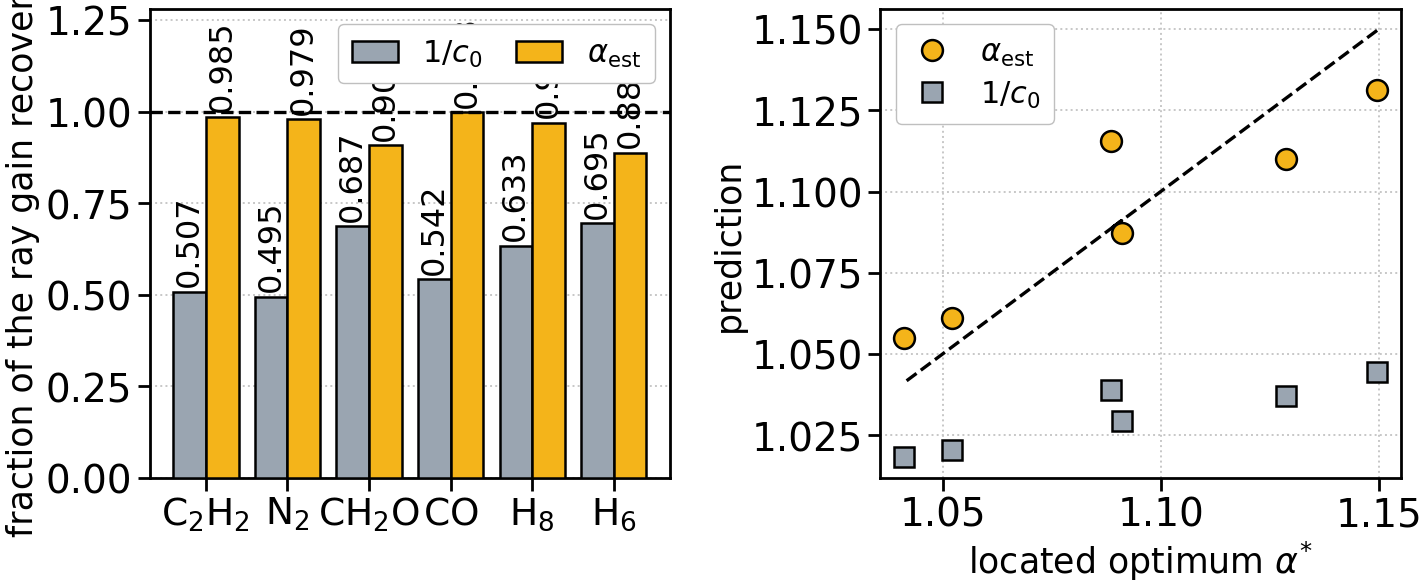

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(15.0, 6.6))
f1 = T3['f(1/c0)'].values; f2 = T3['f(alpha_est)'].values
top = max(1.0, np.nanmax([f1.max(), f2.max()])) * 1.28
axs[0].set_ylim(0, top)
axs[0].bar(x - 0.2, f1, 0.4, color=GREY, edgecolor='black', lw=1.8,
           label=r'$1/c_0$', zorder=3)
axs[0].bar(x + 0.2, f2, 0.4, color=GOLD, edgecolor='black', lw=1.8,
           label=r'$\alpha_{\mathrm{est}}$', zorder=3)
annot(axs[0], x - 0.2, f1, top, '%.3f'); annot(axs[0], x + 0.2, f2, top, '%.3f')
axs[0].axhline(1.0, color='black', ls='--', lw=2.4, zorder=4)
axs[0].set_xticks(x); axs[0].set_xticklabels(labels, fontsize=FS_MOL)
axs[0].set_ylabel('fraction of the ray gain recovered', fontsize=FS_LAB)
axs[0].grid(True, axis='y', zorder=0); axs[0].set_axisbelow(True)
axs[0].legend(loc='upper right', ncol=2, fontsize=FS_LEG)

a_s = T3['alpha*'].values
axs[1].plot(a_s, a_s, 'k--', lw=2.4)
axs[1].plot(a_s, T3['alpha_est'].values, 'o', color=GOLD, ms=15, mec='black',
            mew=1.8, label=r'$\alpha_{\mathrm{est}}$')
axs[1].plot(a_s, T3['1/c0'].values, 's', color=GREY, ms=15, mec='black',
            mew=1.8, label=r'$1/c_0$')
axs[1].set_xlabel(r'located optimum $\alpha^{*}$', fontsize=FS_LAB)
axs[1].set_ylabel('prediction', fontsize=FS_LAB)
axs[1].grid(True, zorder=0); axs[1].set_axisbelow(True)
axs[1].legend(loc='upper left', fontsize=FS_LEG)
save(fig, 'figS2_predictors')

### Figure S3 — parallelism

wrote SI_figS3_parallelism.png


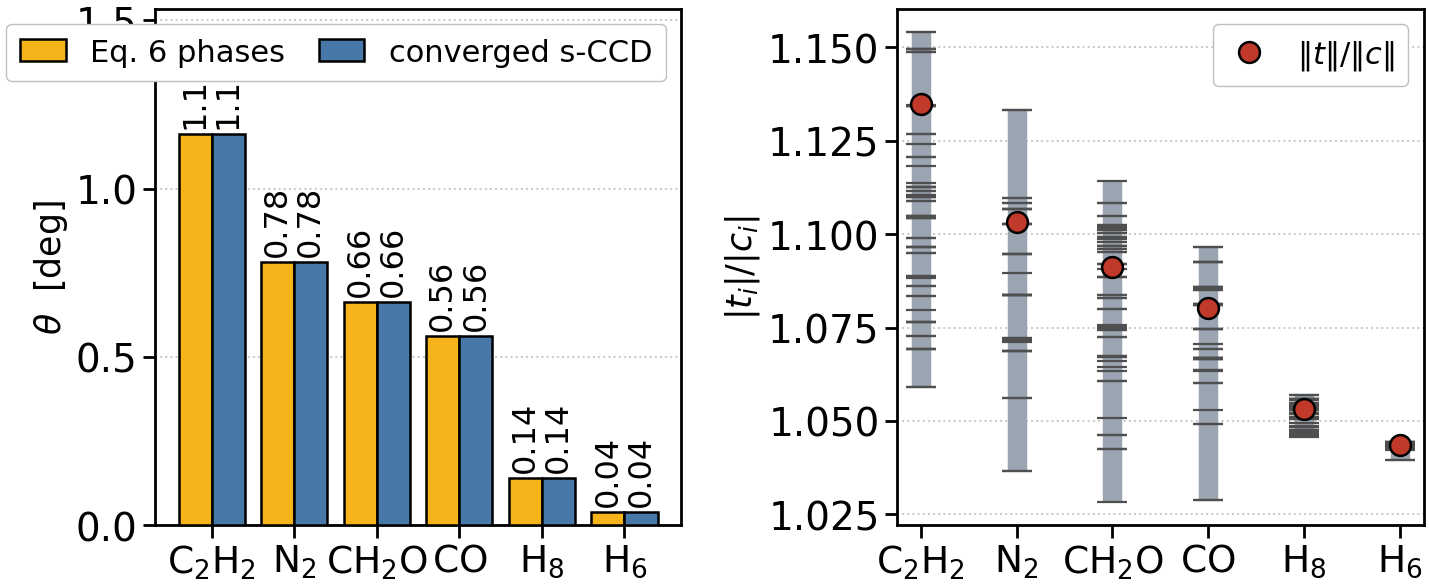

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(15.0, 6.6))
t1 = T4['theta / deg'].values; t2 = T4['theta_sCCD / deg'].values
top = max(t1.max(), t2.max()) * 1.32; axs[0].set_ylim(0, top)
axs[0].bar(x - 0.2, t1, 0.4, color=GOLD, edgecolor='black', lw=1.8,
           label='Eq. 6 phases', zorder=3)
axs[0].bar(x + 0.2, t2, 0.4, color=BLUE, edgecolor='black', lw=1.8,
           label='converged s-CCD', zorder=3)
annot(axs[0], x - 0.2, t1, top, '%.2f'); annot(axs[0], x + 0.2, t2, top, '%.2f')
axs[0].set_xticks(x); axs[0].set_xticklabels(labels, fontsize=FS_MOL)
axs[0].set_ylabel(r'$\theta$  [deg]', fontsize=FS_LAB)
axs[0].grid(True, axis='y', zorder=0); axs[0].set_axisbelow(True)
axs[0].legend(loc='upper right', ncol=2, fontsize=FS_LEG)

for i, m in enumerate(ORDER):
    r = np.asarray(SI[m]['ratios'])
    axs[1].vlines(i, r.min(), r.max(), color=GREY, lw=14, zorder=2)
    axs[1].plot([i]*len(r), r, '_', color=DARK, ms=22, mew=1.6, zorder=3)
    axs[1].plot(i, SI[m]['norm_ratio'], 'o', color=RED, ms=15, mec='black',
                mew=1.8, zorder=5)
axs[1].plot([], [], 'o', color=RED, ms=15, mec='black', mew=1.8,
            label=r'$\|t\|/\|c\|$')
axs[1].set_xticks(x); axs[1].set_xticklabels(labels, fontsize=FS_MOL)
axs[1].set_ylabel(r'$|t_i|/|c_i|$', fontsize=FS_LAB)
axs[1].grid(True, axis='y', zorder=0); axs[1].set_axisbelow(True)
axs[1].legend(loc='upper right', fontsize=FS_LEG)
save(fig, 'figS3_parallelism')

### Figure S4 — cost of the singles block

wrote SI_figS4_gate_cost.png


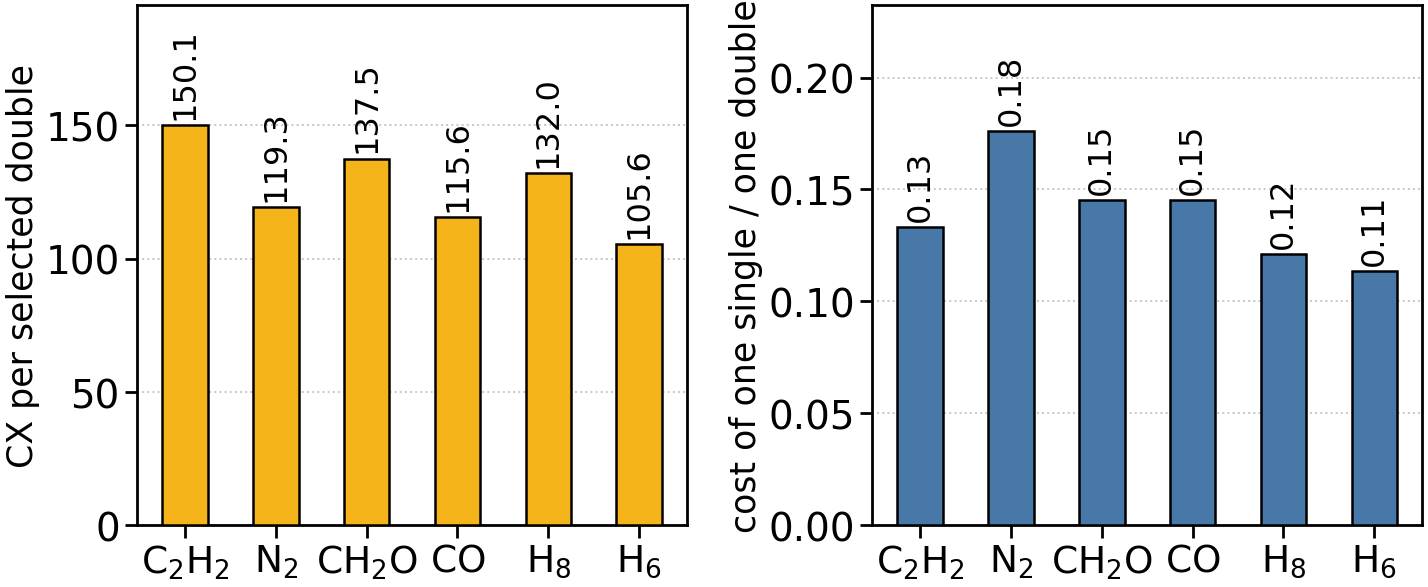

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(15.0, 6.6))
pd_ = T7['CX per double'].values; ps_ = T7['CX per single'].values
top = pd_.max() * 1.30; axs[0].set_ylim(0, top)
axs[0].bar(x, pd_, 0.5, color=GOLD, edgecolor='black', lw=1.8, zorder=3)
annot(axs[0], x, pd_, top, '%.1f')
axs[0].set_xticks(x); axs[0].set_xticklabels(labels, fontsize=FS_MOL)
axs[0].set_ylabel('CX per selected double', fontsize=FS_LAB)
axs[0].grid(True, axis='y', zorder=0); axs[0].set_axisbelow(True)

rel = ps_ / pd_
top2 = np.nanmax(rel) * 1.32; axs[1].set_ylim(0, top2)
axs[1].bar(x, rel, 0.5, color=BLUE, edgecolor='black', lw=1.8, zorder=3)
annot(axs[1], x, rel, top2, '%.2f')
axs[1].set_xticks(x); axs[1].set_xticklabels(labels, fontsize=FS_MOL)
axs[1].set_ylabel('cost of one single / one double', fontsize=FS_LAB)
axs[1].grid(True, axis='y', zorder=0); axs[1].set_axisbelow(True)
save(fig, 'figS4_gate_cost')

### Figure S4 — the noise condition

wrote SI_figS5_sqd_condition.png


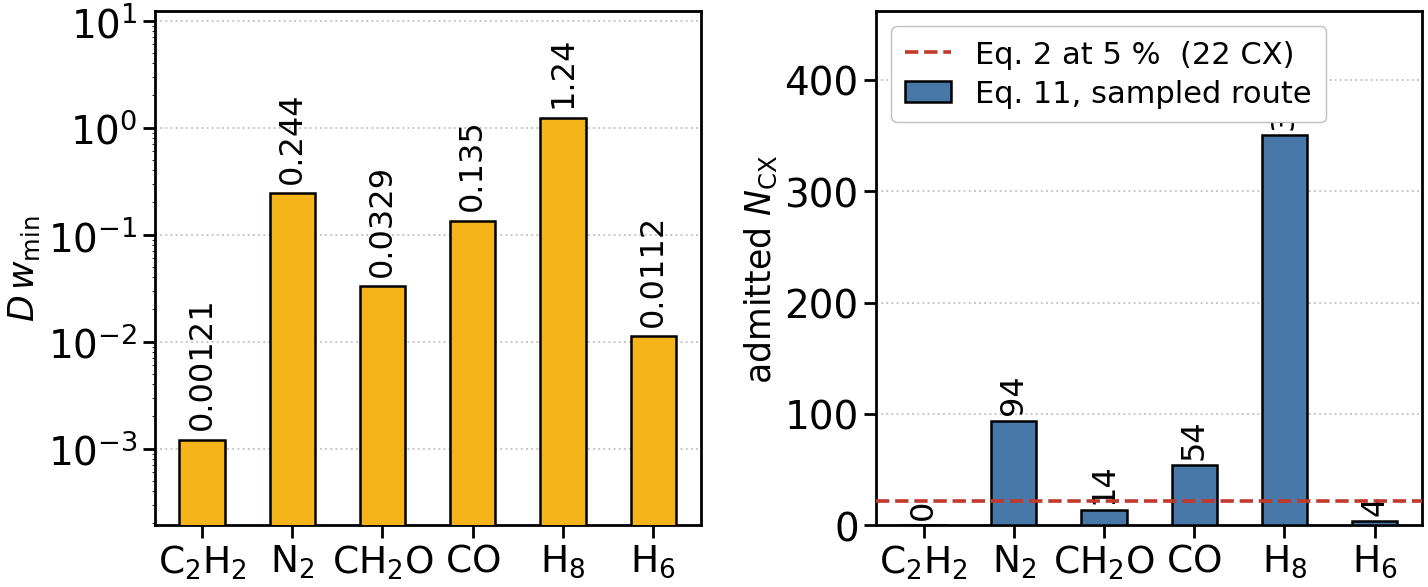

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(15.0, 6.6))
dw = T9['D w_min'].values.astype(float)
axs[0].set_yscale('log')
axs[0].set_ylim(10 ** (np.log10(dw.min()) - 0.8), 10 ** (np.log10(dw.max()) + 1.0))
axs[0].bar(x, dw, 0.5, color=GOLD, edgecolor='black', lw=1.8, zorder=3)
for xi, v in zip(x, dw):
    axs[0].text(xi, v * 1.25, '%.3g' % v, rotation=90, ha='center', va='bottom',
                fontsize=FS_ANNOT)
axs[0].set_xticks(x); axs[0].set_xticklabels(labels, fontsize=FS_MOL)
axs[0].set_ylabel(r'$D\,w_{\min}$', fontsize=FS_LAB)
axs[0].grid(True, axis='y', zorder=0); axs[0].set_axisbelow(True)

nc = T9['N_CX'].values.astype(float)
top = max(nc.max(), 1) * 1.32; axs[1].set_ylim(0, top)
axs[1].bar(x, nc, 0.5, color=BLUE, edgecolor='black', lw=1.8,
           label='Eq. 11, sampled route', zorder=3)
annot(axs[1], x, nc, top, '%.0f')
n_direct = math.floor(math.log(1 - 0.05) / math.log(FIDELITY))
axs[1].axhline(n_direct, color=RED, ls='--', lw=2.6, zorder=4,
               label='Eq. 2 at 5 %%  (%d CX)' % n_direct)
axs[1].set_xticks(x); axs[1].set_xticklabels(labels, fontsize=FS_MOL)
axs[1].set_ylabel(r'admitted $N_{\mathrm{CX}}$', fontsize=FS_LAB)
axs[1].grid(True, axis='y', zorder=0); axs[1].set_axisbelow(True)
axs[1].legend(loc='upper left', fontsize=FS_LEG)
save(fig, 'figS5_sqd_condition')